# Praktikum 9: Convolutional Neural Network
**Mata Kuliah:** Praktikum Penambangan Data
**Nama:** Hafidz Rizqullah Prasetya
**NIM:** 24/535493/SV/24243
**Kelas:** PL5A1
**Dosen Pengampu:** Dr. Imam Fahrurrozi, S.T., M.Cs.
**Program Studi:** D-IV Teknologi Rekayasa Perangkat Lunak
**Departemen:** Teknik Elektro dan Informatika, Sekolah Vokasi UGM

## 1. Percobaan Modul: Klasifikasi Citra Dog vs Cat
### 1.1 Unduh Dataset
Dataset berisi 100 citra (50 kucing, 50 anjing) yang diunduh dari tautan Google Drive modul, lalu dipindahkan ke struktur folder `dataset/cat` dan `dataset/dog`.

In [1]:
import os
import shutil
import zipfile
import urllib.request

DATA_URL = "https://drive.usercontent.google.com/download?id=1hOU0OcYc8_za_0SJLc6HALjVc4sfVGNA&export=download&confirm=t"
urllib.request.urlretrieve(DATA_URL, "datasets.zip")
with zipfile.ZipFile("datasets.zip") as zf:
    zf.extractall(".")

for kelas in ["cat", "dog"]:
    os.makedirs(f"dataset/{kelas}", exist_ok=True)
    for nama in os.listdir(f"cnn/dataset/{kelas}"):
        shutil.move(f"cnn/dataset/{kelas}/{nama}", f"dataset/{kelas}/{nama}")
shutil.rmtree("cnn")

for kelas in sorted(os.listdir("dataset")):
    print(kelas, len(os.listdir(f"dataset/{kelas}")), "citra")

cat 50 citra
dog 50 citra


### 1.2 Impor Pustaka

In [2]:
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, Dropout, Flatten

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


### 1.3 Pembacaan dan Pembagian Dataset
Citra dimuat dengan `ImageDataGenerator`, diubah ke ukuran 224 x 224 piksel, dinormalisasi ke rentang 0 sampai 1, lalu dibagi 80% data latih dan 20% data validasi.

In [3]:
data_path = "dataset/"
base_dir = os.path.join(data_path)

IMAGE_SIZE = 224
BATCH_SIZE = 16

datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1. / 255,
    validation_split=0.2)

train_generator = datagen.flow_from_directory(
    base_dir,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    subset='training',
    seed=SEED)

val_generator = datagen.flow_from_directory(
    base_dir,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    subset='validation',
    shuffle=False)

print(train_generator.class_indices)

Found 80 images belonging to 2 classes.


Found 20 images belonging to 2 classes.


{'cat': 0, 'dog': 1}


### 1.4 Uji Coba Pembacaan Data

(16, 224, 224, 3)


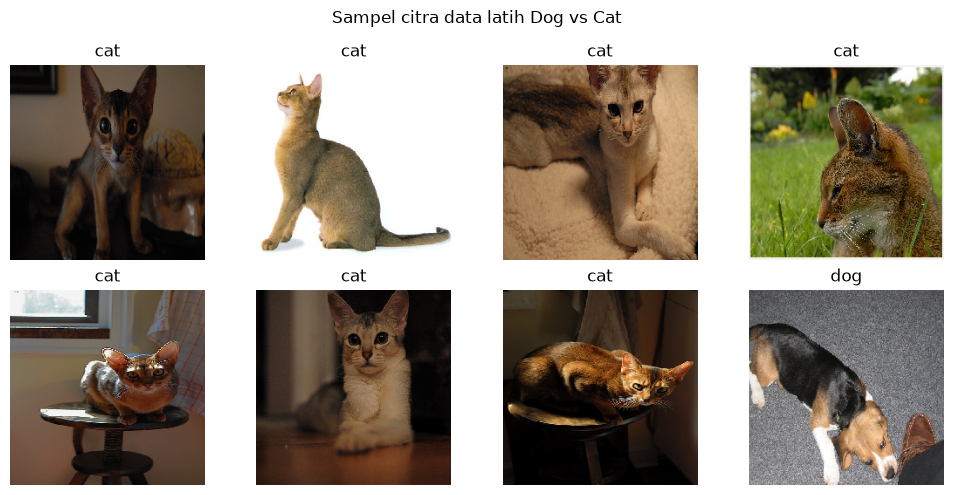

In [4]:
img, label = next(train_generator)
print(img.shape)

nama_kelas = {v: k for k, v in train_generator.class_indices.items()}
plt.figure(figsize=(10, 5))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(img[i])
    plt.title(nama_kelas[np.argmax(label[i])])
    plt.axis('off')
plt.suptitle('Sampel citra data latih Dog vs Cat')
plt.tight_layout()
plt.show()

### 1.5 Cek Bentuk Data (IMG_SHAPE)

In [5]:
for image_batch, label_batch in train_generator:
    break

print(f"Image batch shape: {image_batch.shape}")
print(f"Label batch shape: {label_batch.shape}")

IMG_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)
num_classes = 2
print("IMG_SHAPE:", IMG_SHAPE)
print("num_classes:", num_classes)

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16, 2)
IMG_SHAPE: (224, 224, 3)
num_classes: 2


### 1.6 Membangun Model CNN Sederhana
Model terdiri atas dua blok konvolusi (`Conv2D` + `MaxPooling2D`), lalu `Flatten`, `Dense` 128 neuron, `Dropout`, dan lapisan keluaran `softmax`.

In [6]:
model = Sequential()
model.add(Input(shape=IMG_SHAPE))

model.add(Conv2D(filters=32, kernel_size=3, padding='same', activation='relu'))
model.add(Conv2D(filters=32, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.1))

model.add(Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'))
model.add(Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))

model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,756,066 (98.25 MB)

 Trainable params: 25,756,066 (98.25 MB)

 Non-trainable params: 0 (0.00 B)

### 1.7 Melatih Model

In [7]:
epochs = 20
history = model.fit(train_generator,
                    epochs=epochs,
                    validation_data=val_generator,
                    verbose=2)
loss, acc = model.evaluate(val_generator, verbose=0)
print(f"Validation loss: {loss:.4f}")
print(f"Validation accuracy: {acc:.4f}")

Epoch 1/20


5/5 - 7s - 1s/step - accuracy: 0.4500 - loss: 1.3031 - val_accuracy: 0.5000 - val_loss: 0.6932


Epoch 2/20


5/5 - 6s - 1s/step - accuracy: 0.5125 - loss: 0.6991 - val_accuracy: 0.5000 - val_loss: 0.6906


Epoch 3/20


5/5 - 5s - 1s/step - accuracy: 0.5875 - loss: 0.6875 - val_accuracy: 0.5000 - val_loss: 0.7067


... (31 outputs left out)

5/5 - 5s - 1s/step - accuracy: 0.9625 - loss: 0.1755 - val_accuracy: 0.7000 - val_loss: 0.5423


Epoch 20/20


5/5 - 5s - 1s/step - accuracy: 0.9750 - loss: 0.0999 - val_accuracy: 0.7000 - val_loss: 0.7091


Validation loss: 0.7091
Validation accuracy: 0.7000


### 1.8 Evaluasi Performa Model

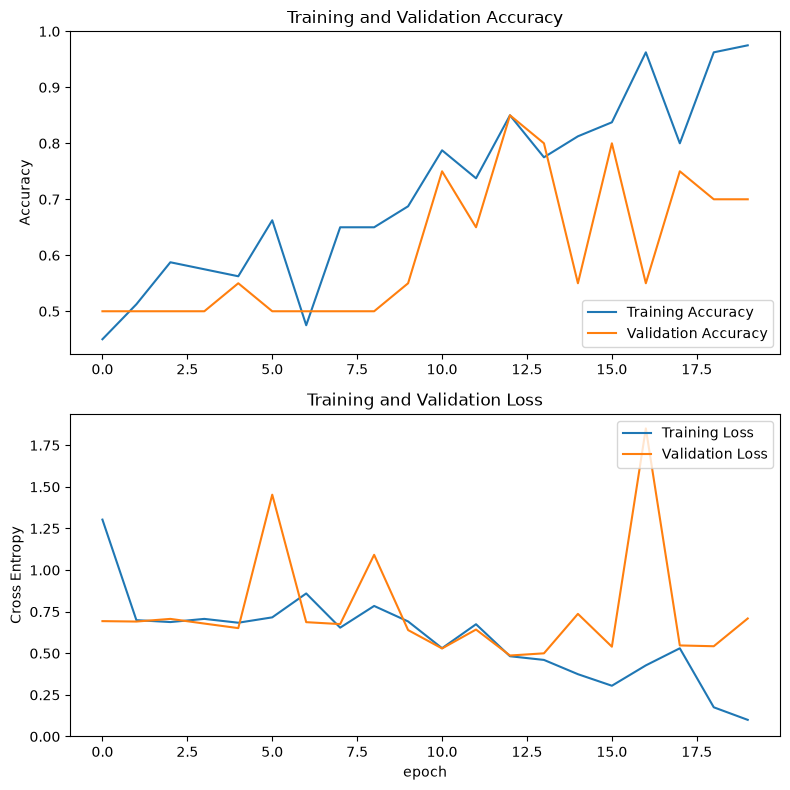

In [8]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()), 1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0, min(max(plt.ylim()), 3)])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.tight_layout()
plt.show()

## 2. Tugas dan Analisis: Klasifikasi Multi-Kelas CIFAR-10
### 2.1 Memuat Dataset CIFAR-10
CIFAR-10 berisi 60.000 citra berwarna 32 x 32 piksel dalam 10 kelas, dimuat langsung dari `tf.keras.datasets`.

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.layers import Rescaling
from tensorflow.keras.callbacks import EarlyStopping

(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("x_train_full:", x_train_full.shape, x_train_full.dtype)
print("x_test      :", x_test.shape)
print("Rentang piksel:", x_train_full.min(), "-", x_train_full.max())
print("Jumlah citra per kelas (latih):")
print(dict(zip(class_names, np.bincount(y_train_full))))

x_train_full: (50000, 32, 32, 3) uint8
x_test      : (10000, 32, 32, 3)
Rentang piksel: 0 - 255
Jumlah citra per kelas (latih):
{'airplane': np.int64(5000), 'automobile': np.int64(5000), 'bird': np.int64(5000), 'cat': np.int64(5000), 'deer': np.int64(5000), 'dog': np.int64(5000), 'frog': np.int64(5000), 'horse': np.int64(5000), 'ship': np.int64(5000), 'truck': np.int64(5000)}


### 2.2 Sampel Citra per Kelas

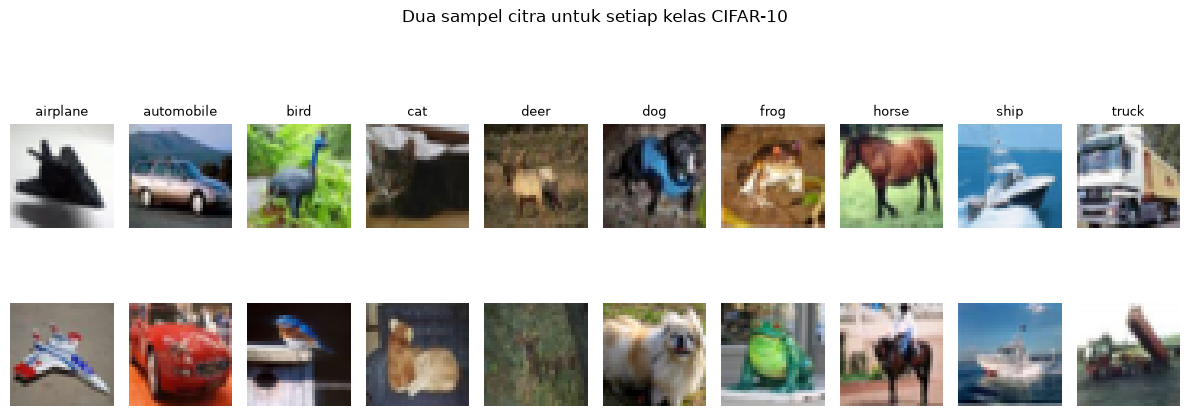

In [10]:
plt.figure(figsize=(12, 5))
for k in range(10):
    idx = np.where(y_train_full == k)[0][:2]
    for j, i in enumerate(idx):
        plt.subplot(2, 10, k + 1 + j * 10)
        plt.imshow(x_train_full[i])
        plt.axis('off')
        if j == 0:
            plt.title(class_names[k], fontsize=9)
plt.suptitle('Dua sampel citra untuk setiap kelas CIFAR-10')
plt.tight_layout()
plt.show()

### 2.3 Pembagian Data Latih, Validasi, dan Uji
Sebanyak 5.000 citra dari data latih disisihkan sebagai data validasi. Data uji 10.000 citra hanya dipakai di akhir.

In [11]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(x_train_full))
val_idx, train_idx = perm[:5000], perm[5000:]

x_train, y_train = x_train_full[train_idx], y_train_full[train_idx]
x_val, y_val = x_train_full[val_idx], y_train_full[val_idx]
del x_train_full, y_train_full

print("Data latih  :", x_train.shape)
print("Data validasi:", x_val.shape)
print("Data uji    :", x_test.shape)

Data latih  : (45000, 32, 32, 3)
Data validasi: (5000, 32, 32, 3)
Data uji    : (10000, 32, 32, 3)


### 2.4 Model Pembanding Tanpa Dropout
Model pertama memakai tiga blok konvolusi dengan `MaxPooling2D` tanpa `Dropout`, sebagai pembanding untuk melihat gejala *overfitting*.

In [12]:
def bangun_cnn(dropout=True):
    m = Sequential(name='cnn_dropout' if dropout else 'cnn_tanpa_dropout')
    m.add(Input(shape=(32, 32, 3)))
    m.add(Rescaling(1. / 255))
    for f, d in [(32, 0.2), (64, 0.3), (128, 0.4)]:
        m.add(Conv2D(f, 3, padding='same', activation='relu'))
        m.add(Conv2D(f, 3, padding='same', activation='relu'))
        m.add(MaxPooling2D((2, 2)))
        if dropout:
            m.add(Dropout(d))
    m.add(Flatten())
    m.add(Dense(256, activation='relu'))
    if dropout:
        m.add(Dropout(0.5))
    m.add(Dense(10, activation='softmax'))
    m.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

tf.random.set_seed(SEED)
model_base = bangun_cnn(dropout=False)
hist_base = model_base.fit(x_train, y_train,
                           epochs=15,
                           batch_size=128,
                           validation_data=(x_val, y_val),
                           verbose=2)

Epoch 1/15


352/352 - 64s - 183ms/step - accuracy: 0.4177 - loss: 1.5800 - val_accuracy: 0.5564 - val_loss: 1.2270


Epoch 2/15


352/352 - 63s - 178ms/step - accuracy: 0.6233 - loss: 1.0594 - val_accuracy: 0.6594 - val_loss: 0.9569


Epoch 3/15


352/352 - 63s - 179ms/step - accuracy: 0.7020 - loss: 0.8505 - val_accuracy: 0.6830 - val_loss: 0.8951


... (20 outputs left out)

Epoch 14/15


352/352 - 64s - 183ms/step - accuracy: 0.9467 - loss: 0.1480 - val_accuracy: 0.7288 - val_loss: 1.4277


Epoch 15/15


352/352 - 64s - 181ms/step - accuracy: 0.9559 - loss: 0.1244 - val_accuracy: 0.7304 - val_loss: 1.6207


### 2.5 Model CNN dengan Regularisasi Dropout
Model kedua memakai arsitektur yang sama, ditambah `Dropout` bertingkat (0,2; 0,3; 0,4; 0,5) dan `EarlyStopping` yang memantau `val_loss`.

In [13]:
tf.random.set_seed(SEED)
model_cnn = bangun_cnn(dropout=True)
model_cnn.summary()

Model: "cnn_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 814,122 (3.11 MB)

 Trainable params: 814,122 (3.11 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
hist_cnn = model_cnn.fit(x_train, y_train,
                         epochs=40,
                         batch_size=128,
                         validation_data=(x_val, y_val),
                         callbacks=[early_stop],
                         verbose=2)
print("Epoch terbaik:", int(np.argmin(hist_cnn.history['val_loss'])) + 1)

Epoch 1/40


352/352 - 68s - 193ms/step - accuracy: 0.2998 - loss: 1.8566 - val_accuracy: 0.4556 - val_loss: 1.4651


Epoch 2/40


352/352 - 67s - 189ms/step - accuracy: 0.4975 - loss: 1.3794 - val_accuracy: 0.5626 - val_loss: 1.1970


Epoch 3/40


352/352 - 66s - 188ms/step - accuracy: 0.5890 - loss: 1.1523 - val_accuracy: 0.6418 - val_loss: 0.9712


... (63 outputs left out)

352/352 - 63s - 180ms/step - accuracy: 0.8504 - loss: 0.4238 - val_accuracy: 0.8240 - val_loss: 0.5288


Epoch 36/40


352/352 - 64s - 180ms/step - accuracy: 0.8551 - loss: 0.4143 - val_accuracy: 0.8238 - val_loss: 0.5246


Epoch terbaik: 31


### 2.6 Grafik Loss dan Akurasi

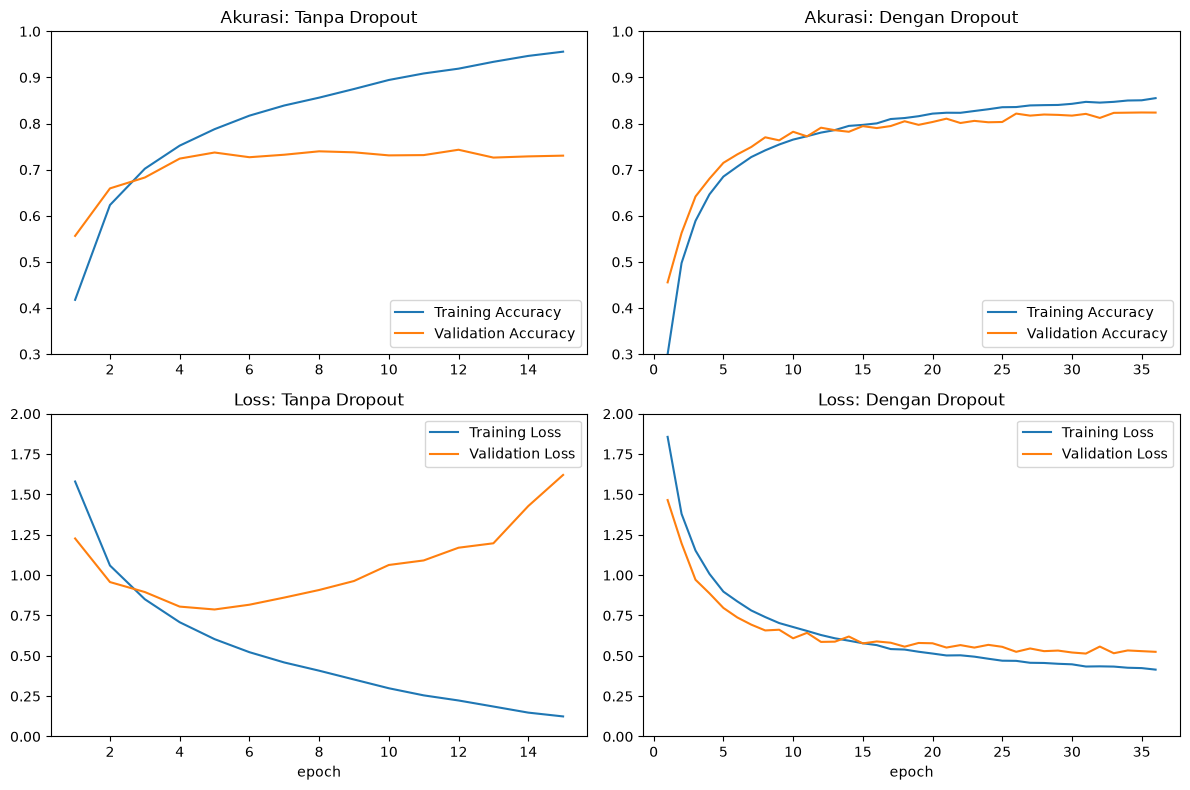

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for kol, (judul, h) in enumerate([('Tanpa Dropout', hist_base), ('Dengan Dropout', hist_cnn)]):
    ep = range(1, len(h.history['loss']) + 1)
    axes[0, kol].plot(ep, h.history['accuracy'], label='Training Accuracy')
    axes[0, kol].plot(ep, h.history['val_accuracy'], label='Validation Accuracy')
    axes[0, kol].set_title(f'Akurasi: {judul}')
    axes[0, kol].set_ylim(0.3, 1.0)
    axes[0, kol].legend(loc='lower right')
    axes[1, kol].plot(ep, h.history['loss'], label='Training Loss')
    axes[1, kol].plot(ep, h.history['val_loss'], label='Validation Loss')
    axes[1, kol].set_title(f'Loss: {judul}')
    axes[1, kol].set_xlabel('epoch')
    axes[1, kol].set_ylim(0, 2.0)
    axes[1, kol].legend(loc='upper right')
plt.tight_layout()
plt.show()

### 2.7 Evaluasi pada Data Uji

In [16]:
hasil = {}
for nama, m in [('Tanpa Dropout', model_base), ('Dengan Dropout', model_cnn)]:
    test_loss, test_acc = m.evaluate(x_test, y_test, verbose=0)
    train_acc = m.evaluate(x_train, y_train, verbose=0)[1]
    hasil[nama] = (train_acc, test_acc, test_loss)
    print(f"{nama:15s} | akurasi latih {train_acc:.4f} | akurasi uji {test_acc:.4f} | loss uji {test_loss:.4f} | selisih {train_acc - test_acc:.4f}")

Tanpa Dropout   | akurasi latih 0.9251 | akurasi uji 0.7355 | loss uji 1.6627 | selisih 0.1896


Dengan Dropout  | akurasi latih 0.9329 | akurasi uji 0.8248 | loss uji 0.5453 | selisih 0.1081


In [17]:
y_prob = model_cnn.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

              precision    recall  f1-score   support

    airplane     0.8490    0.8210    0.8348      1000
  automobile     0.9370    0.9080    0.9223      1000
        bird     0.7510    0.7480    0.7495      1000
         cat     0.7176    0.6200    0.6652      1000
        deer     0.7831    0.8270    0.8045      1000
         dog     0.7598    0.7530    0.7564      1000
        frog     0.7984    0.9030    0.8475      1000
       horse     0.8535    0.8620    0.8577      1000
        ship     0.8935    0.9060    0.8997      1000
       truck     0.8982    0.9000    0.8991      1000

    accuracy                         0.8248     10000
   macro avg     0.8241    0.8248    0.8237     10000
weighted avg     0.8241    0.8248    0.8237     10000



### 2.8 Confusion Matrix

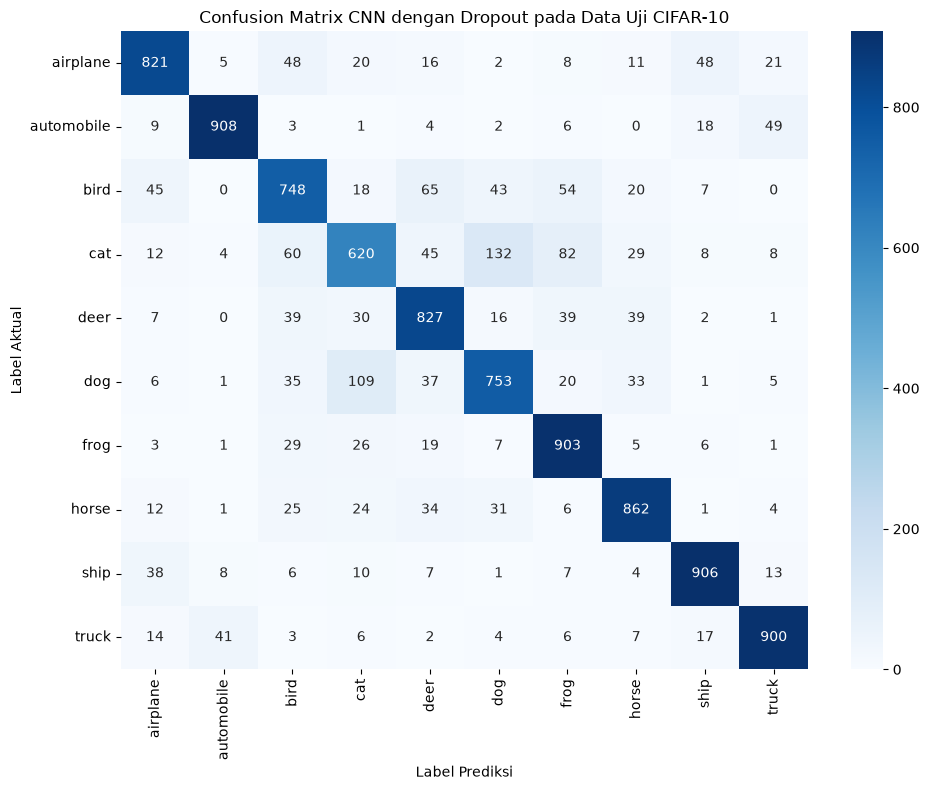

In [18]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Label Prediksi')
plt.ylabel('Label Aktual')
plt.title('Confusion Matrix CNN dengan Dropout pada Data Uji CIFAR-10')
plt.tight_layout()
plt.show()

### 2.9 Contoh Hasil Prediksi

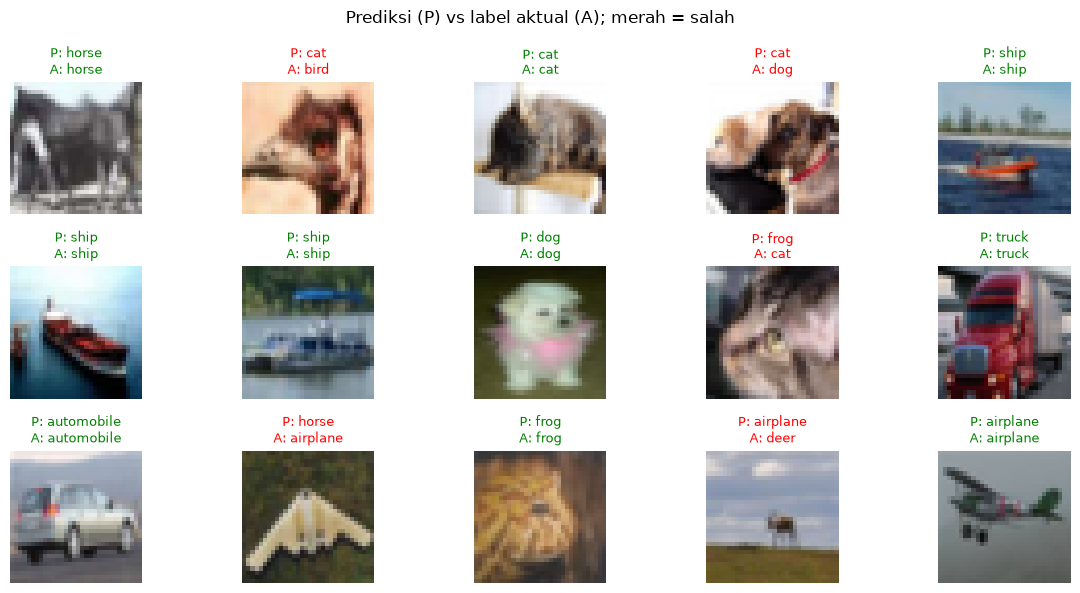

In [19]:
idx = np.random.default_rng(7).choice(len(x_test), 15, replace=False)
plt.figure(figsize=(12, 6))
for n, i in enumerate(idx):
    plt.subplot(3, 5, n + 1)
    plt.imshow(x_test[i])
    benar = y_pred[i] == y_test[i]
    plt.title(f"P: {class_names[y_pred[i]]}\nA: {class_names[y_test[i]]}",
              color='green' if benar else 'red', fontsize=9)
    plt.axis('off')
plt.suptitle('Prediksi (P) vs label aktual (A); merah = salah')
plt.tight_layout()
plt.show()